In [2]:
# CELL 1 – Imports & setup

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from scipy.stats import pearsonr

# ML & preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.cluster import KMeans
import xgboost as xgb
import joblib

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("✅ Imports ready.")


✅ Imports ready.


In [3]:
# CELL 2 – Upload & rename columns

print("⬆️ Please upload SM_addiction.csv")
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
print("Loaded file:", file_name)

df_raw = pd.read_csv(io.BytesIO(uploaded[file_name]))
print("Raw shape:", df_raw.shape)

rename_map = {
    '1. What is your age?': 'age',
    '2. Gender': 'gender',
    '3. Relationship Status': 'relationship_status',
    '4. Occupation Status': 'occupation_status',
    '5. What type of organizations are you affiliated with?': 'org_type',
    '6. Do you use social media?': 'use_sm',
    '7. What social media platforms do you commonly use?': 'platforms',
    '8. What is the average time you spend on social media every day?': 'avg_time_sm',
    '9. How often do you find yourself using Social media without a specific purpose?': 'purposeless_use',
    '10. How often do you get distracted by Social media when you are busy doing something?': 'distracted_busy',
    "11. Do you feel restless if you haven't used Social media in a while?": 'restless_no_sm',
    '12. On a scale of 1 to 5, how easily distracted are you?': 'easily_distracted',
    '13. On a scale of 1 to 5, how much are you bothered by worries?': 'worries',
    '14. Do you find it difficult to concentrate on things?': 'concentration_difficulty',
    '15. On a scale of 1-5, how often do you compare yourself to other successful people through the use of social media?': 'compare_others',
    '16. Following the previous question, how do you feel about these comparisons, generally speaking?': 'feeling_about_comparison',
    '17. How often do you look to seek validation from features of social media?': 'seek_validation',
    '18. How often do you feel depressed or down?': 'depressed',
    '19. On a scale of 1 to 5, how frequently does your interest in daily activities fluctuate?': 'interest_fluctuation',
    '20. On a scale of 1 to 5, how often do you face issues regarding sleep?': 'sleep_issues'
}

df = df_raw.rename(columns=rename_map).copy()
print("Columns after renaming:")
print(df.columns.tolist())

df.head()


⬆️ Please upload SM_addiction.csv


Saving SM_addiction.csv to SM_addiction.csv
Loaded file: SM_addiction.csv
Raw shape: (1502, 20)
Columns after renaming:
['age', 'gender', 'relationship_status', 'occupation_status', 'org_type', 'use_sm', 'platforms', 'avg_time_sm', 'purposeless_use', 'distracted_busy', 'restless_no_sm', 'easily_distracted', 'worries', 'concentration_difficulty', 'compare_others', 'feeling_about_comparison', 'seek_validation', 'depressed', 'interest_fluctuation', 'sleep_issues']


,age,gender,relationship_status,occupation_status,org_type,use_sm,platforms,avg_time_sm,purposeless_use,distracted_busy,restless_no_sm,easily_distracted,worries,concentration_difficulty,compare_others,feeling_about_comparison,seek_validation,depressed,interest_fluctuation,sleep_issues
0,21.0,Male,In a relationship,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",Between 2 and 3 hours,5,3,2,5,2,5,2,3,2,5,4,5
1,21.0,Female,Single,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",More than 5 hours,4,3,2,4,5,4,5,1,1,5,4,5
2,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram, YouTube, Pinterest",Between 3 and 4 hours,3,2,1,2,5,4,3,3,1,4,2,5
3,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram",More than 5 hours,4,2,1,3,5,3,5,1,2,4,3,2
4,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram, YouTube",Between 2 and 3 hours,3,5,4,4,5,5,3,3,3,4,4,1


In [4]:
# CELL 3 – Core cleaning

# Keep only social media users
df = df[df['use_sm'] == 'Yes'].copy()
df.drop(columns=['use_sm'], inplace=True)
print("After keeping only SM users:", df.shape)

# Clean gender
def clean_gender(g):
    if pd.isna(g):
        return np.nan
    g = str(g).strip().lower()
    if g in ['male', 'm']:
        return 'Male'
    if g in ['female', 'f']:
        return 'Female'
    return 'Non-binary/Other'

df['gender_clean'] = df['gender'].apply(clean_gender)

# Clean org_type
df['org_type'] = df['org_type'].fillna('Unknown')
df['org_type'] = df['org_type'].replace({'Goverment': 'Government'})

# Age as numeric
df['age'] = pd.to_numeric(df['age'], errors='coerce')

# Map average time on SM → numeric hours
time_map = {
    'Less than an Hour': 0.5,
    'Between 1 and 2 hours': 1.5,
    'Between 2 and 3 hours': 2.5,
    'Between 3 and 4 hours': 3.5,
    'Between 4 and 5 hours': 4.5,
    'More than 5 hours': 5.5
}
df['avg_time_sm_hours'] = df['avg_time_sm'].map(time_map)

# Number of platforms
df['num_platforms'] = df['platforms'].astype(str).apply(
    lambda x: len([p for p in x.split(',') if p.strip() != ''])
)

# Likert → numeric
likert_cols = [
    'purposeless_use', 'distracted_busy', 'restless_no_sm',
    'easily_distracted', 'worries', 'concentration_difficulty',
    'compare_others', 'feeling_about_comparison',
    'seek_validation', 'depressed',
    'interest_fluctuation', 'sleep_issues'
]
for c in likert_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# Drop rows missing critical numeric fields
critical_numeric = ['age', 'avg_time_sm_hours'] + likert_cols
df = df.dropna(subset=critical_numeric).copy()
print("After dropping rows with critical NaNs:", df.shape)

df.describe()


After keeping only SM users: (1491, 19)
After dropping rows with critical NaNs: (1491, 22)


,age,purposeless_use,distracted_busy,restless_no_sm,easily_distracted,worries,concentration_difficulty,compare_others,feeling_about_comparison,seek_validation,depressed,interest_fluctuation,sleep_issues,avg_time_sm_hours,num_platforms
count,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000,1491.000000
mean,25.865929,3.582160,3.362844,2.614353,3.347418,3.484909,3.274313,2.854460,2.715627,2.445339,3.264923,3.207914,3.213950,3.447015,4.258887
std,9.624168,1.124673,1.325208,1.238437,1.194517,1.302143,1.338838,1.396885,1.052777,1.241426,1.299033,1.260539,1.451856,1.575146,1.987895
min,13.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.500000,1.000000
25%,21.000000,3.000000,2.000000,2.000000,3.000000,3.000000,2.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.500000,3.000000
50%,22.000000,4.000000,4.000000,3.000000,3.000000,4.000000,3.000000,3.000000,3.000000,2.000000,3.000000,3.000000,4.000000,3.500000,4.000000
75%,26.000000,4.000000,5.000000,3.000000,4.000000,5.000000,4.000000,4.000000,3.000000,3.000000,4.000000,4.000000,5.000000,4.500000,6.000000
max,91.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.500000,9.000000


In [5]:
# CELL 4 – Feature engineering

# Passive and active indices
passive_vars = ['avg_time_sm_hours', 'purposeless_use', 'compare_others']
active_vars  = ['seek_validation', 'distracted_busy']

df['passive_index'] = df[passive_vars].mean(axis=1)
df['active_index']  = df[active_vars].mean(axis=1)
df['active_minus_passive'] = df['active_index'] - df['passive_index']

# Psychological burden composite
psych_vars = ['depressed', 'worries', 'sleep_issues', 'concentration_difficulty']
df['psych_burden'] = df[psych_vars].mean(axis=1)

# Additional engineered features
df['passive_active_ratio'] = df['passive_index'] / (df['active_index'] + 1e-3)
df['time_per_platform'] = df['avg_time_sm_hours'] / (df['num_platforms'] + 1e-3)
df['passive_x_time'] = df['passive_index'] * df['avg_time_sm_hours']
df['worries_x_sleep'] = df['worries'] * df['sleep_issues']

# Age groups
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 20, 30, 100],
    labels=['<=20', '21–30', '31+']
)

print("New engineered columns:")
print([
    'passive_index', 'active_index', 'active_minus_passive',
    'psych_burden', 'passive_active_ratio', 'time_per_platform',
    'passive_x_time', 'worries_x_sleep', 'age_group'
])

df[['age', 'avg_time_sm_hours', 'passive_index',
    'active_index', 'active_minus_passive',
    'psych_burden']].head()


New engineered columns:
['passive_index', 'active_index', 'active_minus_passive', 'psych_burden', 'passive_active_ratio', 'time_per_platform', 'passive_x_time', 'worries_x_sleep', 'age_group']


,age,avg_time_sm_hours,passive_index,active_index,active_minus_passive,psych_burden
0,21.0,2.5,3.166667,2.5,-0.666667,4.25
1,21.0,5.5,4.833333,2.0,-2.833333,4.75
2,21.0,3.5,3.166667,1.5,-1.666667,4.50
3,21.0,5.5,4.833333,2.0,-2.833333,3.50
4,21.0,2.5,2.833333,4.0,1.166667,3.75


In [6]:
# CELL 5 – Save cleaned dataset + distributions

clean_name = "SM_addiction_cleaned.csv"
df.to_csv(clean_name, index=False)
print(f"✅ Cleaned dataset saved as: {clean_name}")

print("\nGender distribution:")
print(df['gender_clean'].value_counts(dropna=False))

print("\nRelationship status distribution:")
print(df['relationship_status'].value_counts(dropna=False))

print("\nOccupation status distribution:")
print(df['occupation_status'].value_counts(dropna=False))


✅ Cleaned dataset saved as: SM_addiction_cleaned.csv

Gender distribution:
gender_clean
Female              805
Male                661
Non-binary/Other     25
Name: count, dtype: int64

Relationship status distribution:
relationship_status
Single               884
Married              315
In a relationship    273
Divorced              19
Name: count, dtype: int64

Occupation status distribution:
occupation_status
University Student    900
Salaried Worker       419
School Student        147
Retired                25
Name: count, dtype: int64


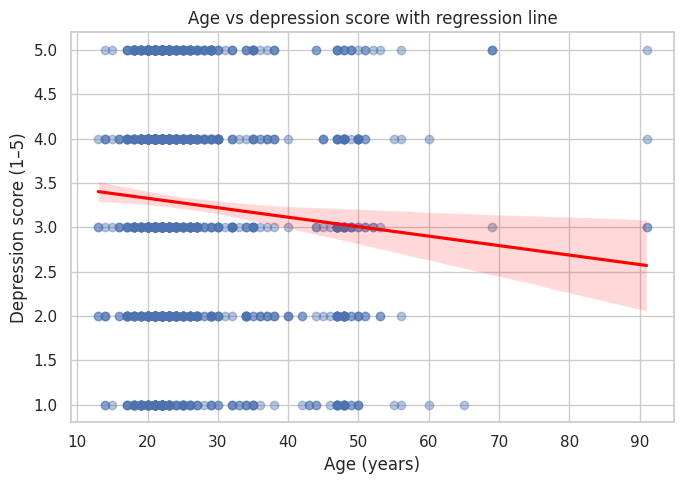

Pearson r between age and depression: -0.079 (p = 0.0022)

Mean depression score by age group:
age_group
<=20     3.247458
21–30    3.356992
31+      2.940476
Name: depressed, dtype: float64


/tmp/ipykernel_11000/3889380787.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('age_group')['depressed'].mean())


In [7]:
# CELL 6 – Age vs depression

plt.figure(figsize=(7,5))
sns.regplot(
    data=df,
    x='age',
    y='depressed',
    scatter_kws={'alpha':0.4},
    line_kws={'color':'red'}
)
plt.xlabel("Age (years)")
plt.ylabel("Depression score (1–5)")
plt.title("Age vs depression score with regression line")
plt.tight_layout()
plt.show()

valid = df[['age', 'depressed']].dropna()
r, p = pearsonr(valid['age'], valid['depressed'])
print(f"Pearson r between age and depression: {r:.3f} (p = {p:.4f})")

print("\nMean depression score by age group:")
print(df.groupby('age_group')['depressed'].mean())


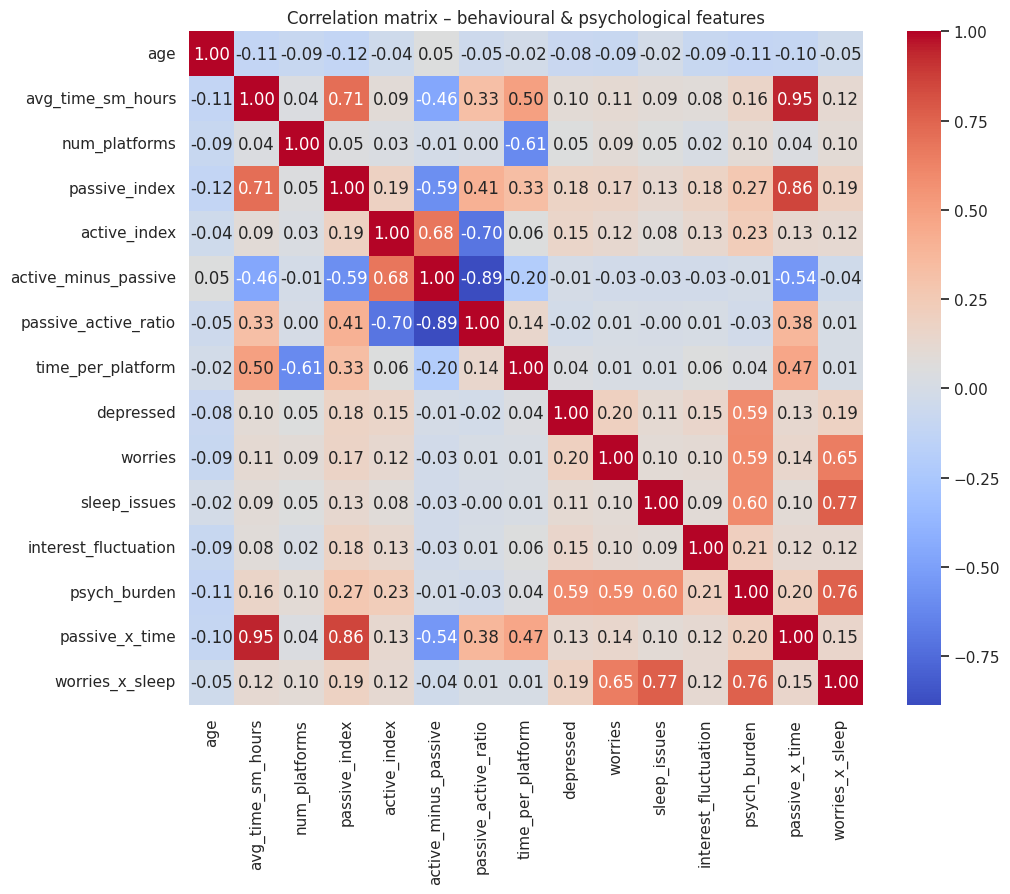

In [8]:
# CELL 7 – Single strengthened correlation matrix

corr_cols = [
    'age', 'avg_time_sm_hours', 'num_platforms',
    'passive_index', 'active_index', 'active_minus_passive',
    'passive_active_ratio', 'time_per_platform',
    'depressed', 'worries', 'sleep_issues',
    'interest_fluctuation', 'psych_burden',
    'passive_x_time', 'worries_x_sleep'
]

corr = df[corr_cols].corr()

plt.figure(figsize=(11,9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation matrix – behavioural & psychological features")
plt.tight_layout()
plt.show()


In [9]:
# CELL 8 – Features, target, train/test split, preprocessor

# Binary target: high depression (4–5) vs low (1–3)
df['depressed_high'] = (df['depressed'] >= 4).astype(int)

numeric_features = [
    'age',
    'avg_time_sm_hours',
    'num_platforms',
    'passive_index',
    'active_index',
    'active_minus_passive',
    'passive_active_ratio',
    'time_per_platform',
    'worries',
    'sleep_issues',
    'interest_fluctuation',
    'psych_burden',
    'passive_x_time',
    'worries_x_sleep'
]

categorical_features = [
    'gender_clean',
    'relationship_status',
    'occupation_status',
    'org_type',
    'age_group'
]

X = df[numeric_features + categorical_features]
y = df['depressed_high']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
print("\nClass balance in y_train:")
print(y_train.value_counts(normalize=True))

numeric_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

print("\n✅ Preprocessor ready.")


Train shape: (1192, 19) Test shape: (299, 19)

Class balance in y_train:
depressed_high
0    0.536913
1    0.463087
Name: proportion, dtype: float64

✅ Preprocessor ready.


In [10]:
# CELL 9 – Baseline Logistic Regression

log_clf = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=300,
            class_weight="balanced",
            solver="lbfgs"
        ))
    ]
)

log_clf.fit(X_train, y_train)

y_pred_log = log_clf.predict(X_test)
y_prob_log = log_clf.predict_proba(X_test)[:, 1]

baseline_results = {
    "Model": "LogisticRegression (baseline)",
    "Accuracy": accuracy_score(y_test, y_pred_log),
    "Precision": precision_score(y_test, y_pred_log),
    "Recall": recall_score(y_test, y_pred_log),
    "F1": f1_score(y_test, y_pred_log),
    "ROC_AUC": roc_auc_score(y_test, y_prob_log)
}

print("=== BASELINE LOGISTIC REGRESSION – TEST SET ===")
for k, v in baseline_results.items():
    if k == "Model":
        print(f"{k}: {v}")
    else:
        print(f"{k}: {v:.3f}")


=== BASELINE LOGISTIC REGRESSION – TEST SET ===
Model: LogisticRegression (baseline)
Accuracy: 0.776
Precision: 0.738
Recall: 0.797
F1: 0.767
ROC_AUC: 0.865


In [11]:
# CELL 10 – Tuned XGBoost with cross-validation

xgb_base = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", xgb.XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_jobs=-1,
            random_state=42
        ))
    ]
)

param_grid = {
    "model__n_estimators": [200, 400, 600],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=15,
    scoring="roc_auc",
    cv=cv,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

print("🔍 Running XGBoost hyperparameter tuning…")
xgb_search.fit(X_train, y_train)

print("\nBest parameters found:")
print(xgb_search.best_params_)

best_xgb = xgb_search.best_estimator_

y_pred_xgb = best_xgb.predict(X_test)
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

xgb_results = {
    "Model": "XGBoost (Tuned)",
    "Accuracy": accuracy_score(y_test, y_pred_xgb),
    "Precision": precision_score(y_test, y_pred_xgb),
    "Recall": recall_score(y_test, y_pred_xgb),
    "F1": f1_score(y_test, y_pred_xgb),
    "ROC_AUC": roc_auc_score(y_test, y_prob_xgb)
}

print("\n=== TUNED XGBOOST – TEST SET ===")
for k, v in xgb_results.items():
    if k == "Model":
        print(f"{k}: {v}")
    else:
        print(f"{k}: {v:.3f}")


🔍 Running XGBoost hyperparameter tuning…
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best parameters found:
{'model__subsample': 1.0, 'model__n_estimators': 200, 'model__max_depth': 4, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0}

=== TUNED XGBOOST – TEST SET ===
Model: XGBoost (Tuned)
Accuracy: 0.766
Precision: 0.774
Recall: 0.696
F1: 0.733
ROC_AUC: 0.866


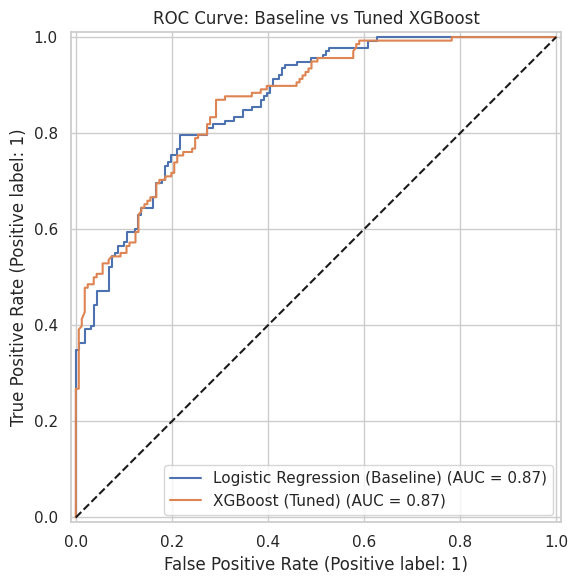

In [12]:
# CELL 11 – ROC Curves

plt.figure(figsize=(8,6))
RocCurveDisplay.from_predictions(
    y_test, y_prob_log, name="Logistic Regression (Baseline)", ax=plt.gca()
)
RocCurveDisplay.from_predictions(
    y_test, y_prob_xgb, name="XGBoost (Tuned)", ax=plt.gca()
)
plt.plot([0,1],[0,1],'k--')
plt.title("ROC Curve: Baseline vs Tuned XGBoost")
plt.tight_layout()
plt.show()


Confusion Matrix (Table Format):
             Pred Low  Pred High
Actual Low        133         28
Actual High        42         96


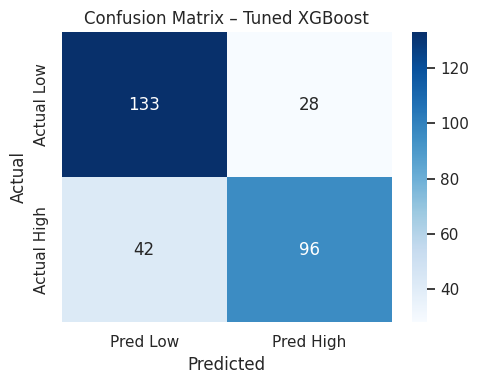

In [13]:
# CELL 12 – Confusion Matrix (Tuned XGBoost)

cm = confusion_matrix(y_test, y_pred_xgb)
cm_df = pd.DataFrame(cm,
                     index=["Actual Low", "Actual High"],
                     columns=["Pred Low", "Pred High"])

print("Confusion Matrix (Table Format):")
print(cm_df)

plt.figure(figsize=(5,4))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix – Tuned XGBoost")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


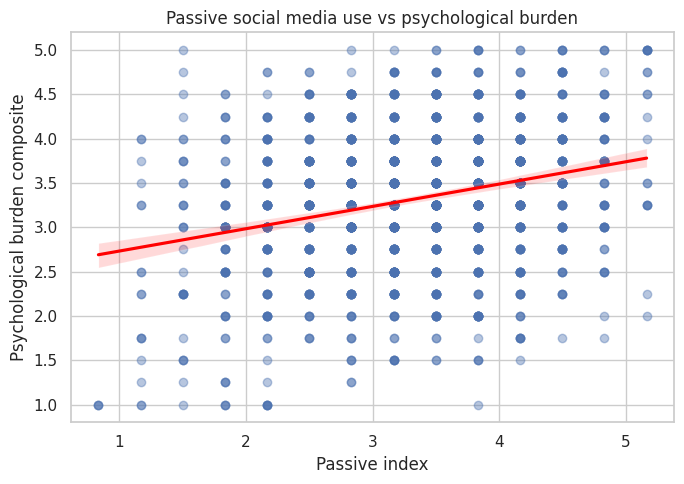

Pearson r between passive_index and psych_burden: 0.269 (p = 0.0000)


In [14]:
# CELL 13 – Passive behaviour vs psychological burden

plt.figure(figsize=(7,5))
sns.regplot(
    data=df,
    x='passive_index',
    y='psych_burden',
    scatter_kws={'alpha':0.4},
    line_kws={'color':'red'}
)
plt.xlabel("Passive index")
plt.ylabel("Psychological burden composite")
plt.title("Passive social media use vs psychological burden")
plt.tight_layout()
plt.show()

valid = df[['passive_index', 'psych_burden']].dropna()
r_pb, p_pb = pearsonr(valid['passive_index'], valid['psych_burden'])
print(f"Pearson r between passive_index and psych_burden: {r_pb:.3f} (p = {p_pb:.4f})")


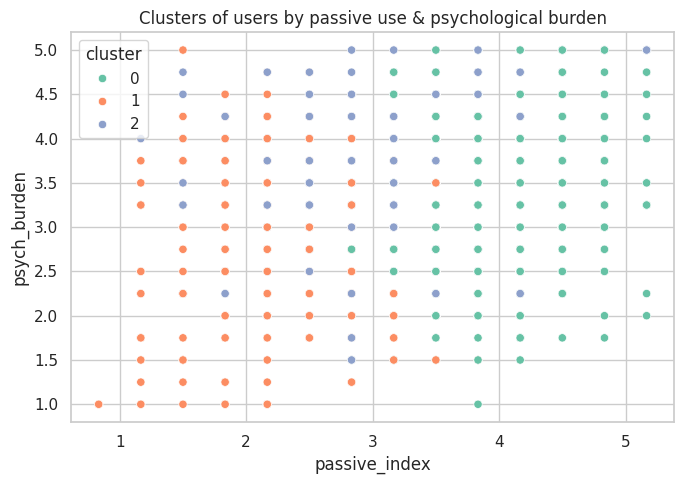

Cluster sizes:
cluster
0    615
2    457
1    419
Name: count, dtype: int64


In [15]:
# CELL 14 – KMeans clustering (brief)

cluster_features = df[[
    'passive_index', 'active_index', 'active_minus_passive',
    'psych_burden', 'avg_time_sm_hours', 'num_platforms'
]]

scaled = StandardScaler().fit_transform(cluster_features)

kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(scaled)

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x='passive_index',
    y='psych_burden',
    hue='cluster',
    palette='Set2'
)
plt.title("Clusters of users by passive use & psychological burden")
plt.tight_layout()
plt.show()

print("Cluster sizes:")
print(df['cluster'].value_counts())


In [16]:
# CELL 15 – Regression: predict depression score

X_reg = df[numeric_features + categorical_features]
y_reg = df['depressed'].astype(float)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

reg_pipe = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

reg_pipe.fit(X_train_r, y_train_r)
y_pred_r = reg_pipe.predict(X_test_r)

from sklearn.metrics import mean_squared_error, r2_score
rmse_r = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
r2_r = r2_score(y_test_r, y_pred_r)

print("=== REGRESSION – Depression score ===")
print(f"R²:   {r2_r:.3f}")
print(f"RMSE: {rmse_r:.3f}")


=== REGRESSION – Depression score ===
R²:   0.523
RMSE: 0.871


In [17]:
# CELL 16 – Save tuned model

joblib.dump(best_xgb, "final_xgb_model.pkl")
print("💾 Tuned XGBoost model saved as final_xgb_model.pkl")


💾 Tuned XGBoost model saved as final_xgb_model.pkl


In [18]:
# CELL 17 – Load model & re-evaluate on unseen test set

loaded_model = joblib.load("final_xgb_model.pkl")
loaded_pred = loaded_model.predict(X_test)
loaded_prob = loaded_model.predict_proba(X_test)[:, 1]

print("=== FINAL MODEL EVALUATION (Loaded model on test set) ===")
print(f"Accuracy:  {accuracy_score(y_test, loaded_pred):.3f}")
print(f"Precision: {precision_score(y_test, loaded_pred):.3f}")
print(f"Recall:    {recall_score(y_test, loaded_pred):.3f}")
print(f"F1:        {f1_score(y_test, loaded_pred):.3f}")
print(f"ROC_AUC:   {roc_auc_score(y_test, loaded_prob):.3f}")


=== FINAL MODEL EVALUATION (Loaded model on test set) ===
Accuracy:  0.766
Precision: 0.774
Recall:    0.696
F1:        0.733
ROC_AUC:   0.866


In [19]:
# CELL 18 – Conference-style results table

results_df = pd.DataFrame([
    baseline_results,
    xgb_results
])

results_df


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,LogisticRegression (baseline),0.775920,0.738255,0.797101,0.766551,0.865469
1,XGBoost (Tuned),0.765886,0.774194,0.695652,0.732824,0.866100


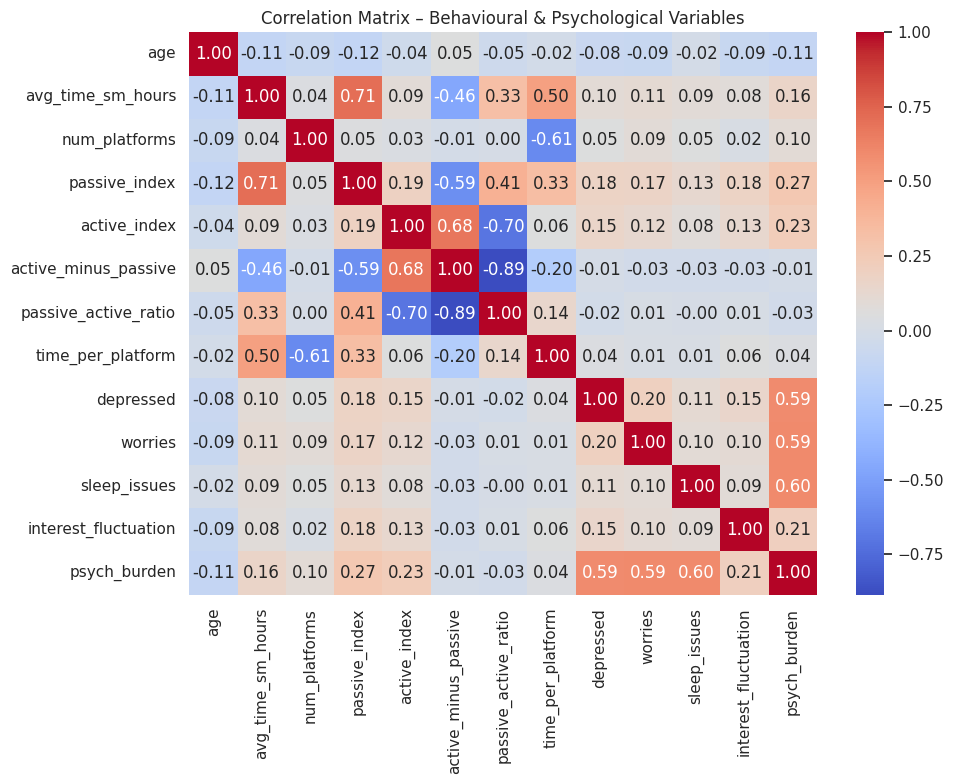

In [20]:
# NEW CELL 7 – Final strengthened correlation matrix

selected_corr_cols = [
    'age',
    'avg_time_sm_hours',
    'num_platforms',
    'passive_index',
    'active_index',
    'active_minus_passive',
    'passive_active_ratio',
    'time_per_platform',
    'depressed',
    'worries',
    'sleep_issues',
    'interest_fluctuation',
    'psych_burden'
]

corr = df[selected_corr_cols].corr()

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=False)
plt.title("Correlation Matrix – Behavioural & Psychological Variables")
plt.tight_layout()
plt.show()


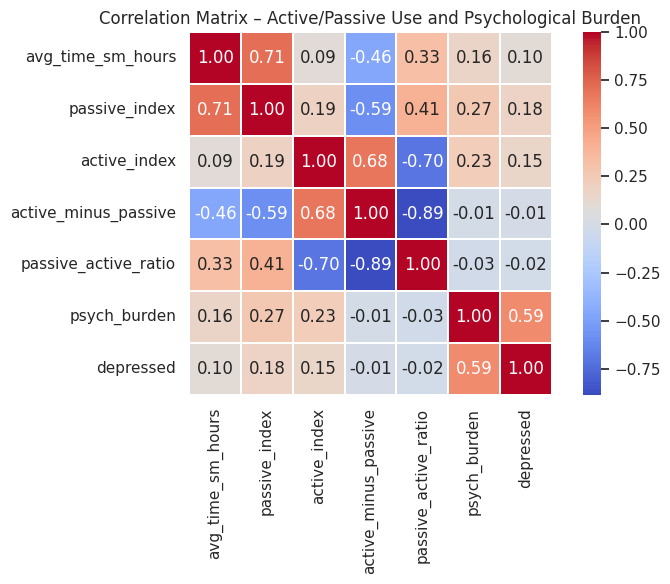

In [21]:
# UPDATED CORRELATION MATRIX – focused on active/passive & psychological burden

corr_cols_core = [
    'avg_time_sm_hours',
    'passive_index',
    'active_index',
    'active_minus_passive',
    'passive_active_ratio',
    'psych_burden',
    'depressed'
]

corr_core = df[corr_cols_core].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_core,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.3
)
plt.title("Correlation Matrix – Active/Passive Use and Psychological Burden")
plt.tight_layout()
plt.show()


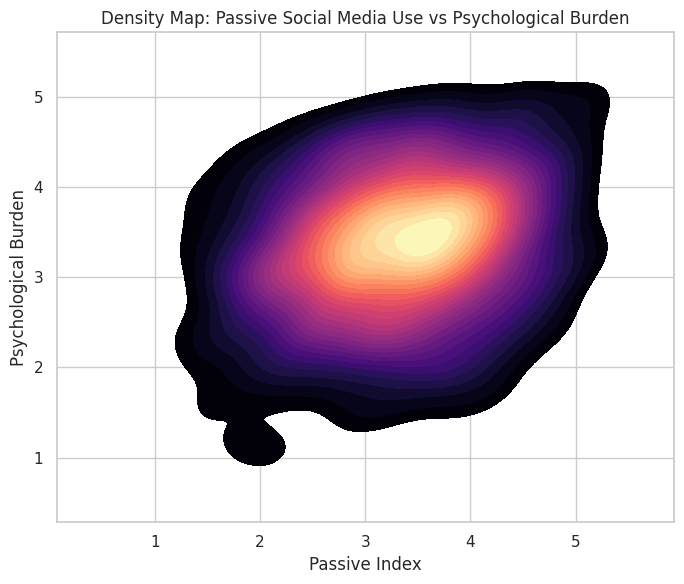

In [22]:
# CELL 19 – 2D density: Passive use vs psychological burden

plt.figure(figsize=(7, 6))
sns.kdeplot(
    data=df,
    x="passive_index",
    y="psych_burden",
    fill=True,
    cmap="magma",
    thresh=0.05,
    levels=30
)
plt.title("Density Map: Passive Social Media Use vs Psychological Burden")
plt.xlabel("Passive Index")
plt.ylabel("Psychological Burden")
plt.tight_layout()
plt.show()


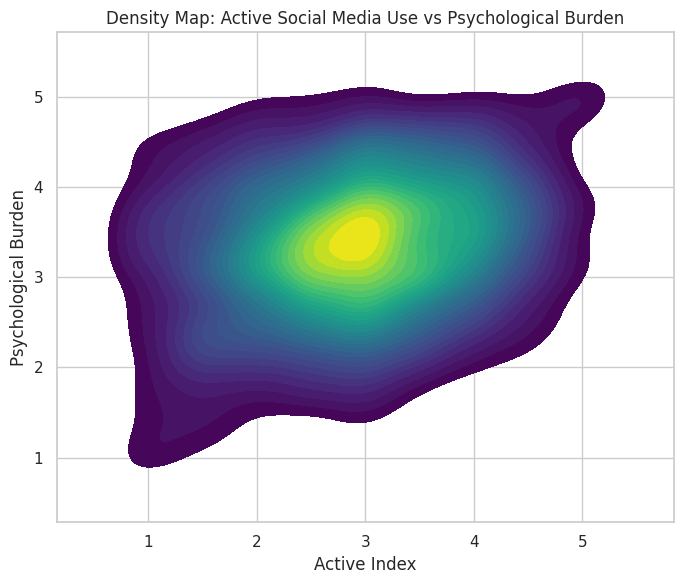

In [23]:
# CELL 20 – 2D density: Active use vs psychological burden

plt.figure(figsize=(7, 6))
sns.kdeplot(
    data=df,
    x="active_index",
    y="psych_burden",
    fill=True,
    cmap="viridis",
    thresh=0.05,
    levels=30
)
plt.title("Density Map: Active Social Media Use vs Psychological Burden")
plt.xlabel("Active Index")
plt.ylabel("Psychological Burden")
plt.tight_layout()
plt.show()


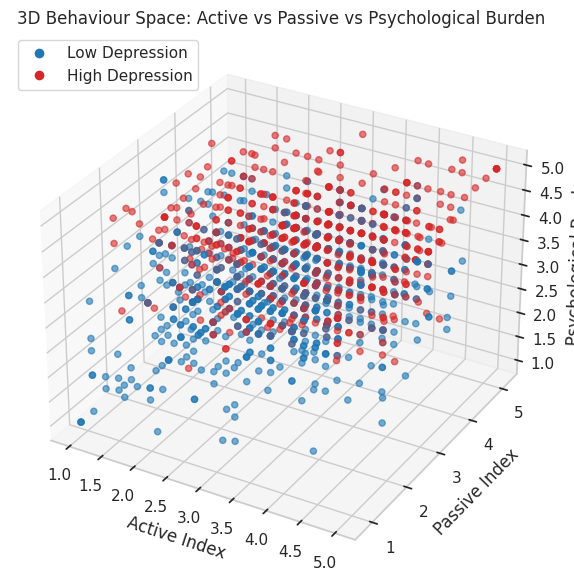

In [24]:
# CELL 21 – 3D scatter: Active vs Passive vs Psychological Burden

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

# Colour by high vs low depression
colors = df['depressed_high'].map({0: 'tab:blue', 1: 'tab:red'})

ax.scatter(
    df['active_index'],
    df['passive_index'],
    df['psych_burden'],
    c=colors,
    alpha=0.6
)

ax.set_xlabel("Active Index")
ax.set_ylabel("Passive Index")
ax.set_zlabel("Psychological Burden")
ax.set_title("3D Behaviour Space: Active vs Passive vs Psychological Burden")

# Manual legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Low Depression',
           markerfacecolor='tab:blue', markersize=8),
    Line2D([0], [0], marker='o', color='w', label='High Depression',
           markerfacecolor='tab:red', markersize=8),
]
ax.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()


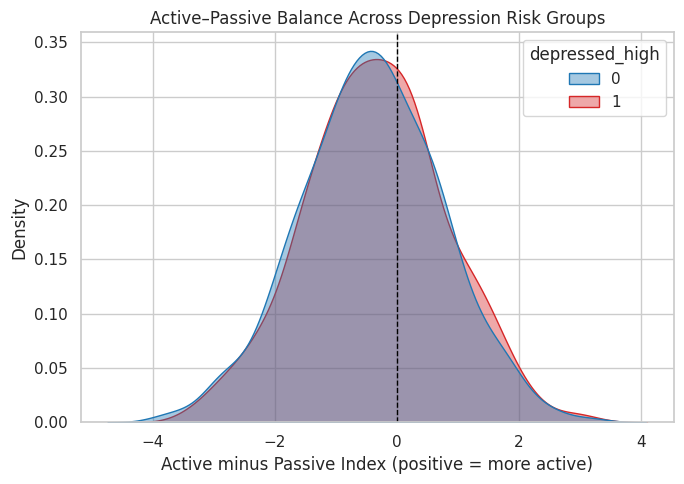

In [25]:
# CELL 22 – Distribution of active–passive balance by depression risk

plt.figure(figsize=(7, 5))
sns.kdeplot(
    data=df,
    x="active_minus_passive",
    hue="depressed_high",
    common_norm=False,
    fill=True,
    alpha=0.4,
    palette={0: "tab:blue", 1: "tab:red"}
)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Active–Passive Balance Across Depression Risk Groups")
plt.xlabel("Active minus Passive Index (positive = more active)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


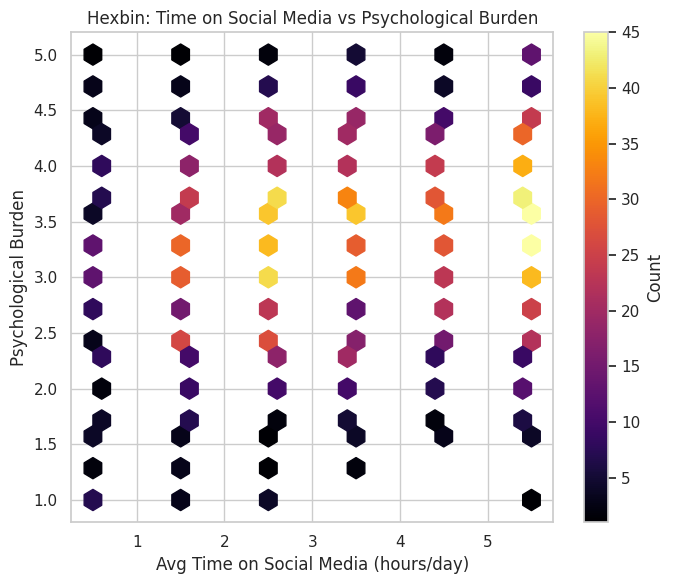

In [26]:
# CELL 23 – Hexbin: Time on SM vs Psychological Burden, coloured by density

plt.figure(figsize=(7, 6))
hb = plt.hexbin(
    df['avg_time_sm_hours'],
    df['psych_burden'],
    gridsize=25,
    cmap="inferno",
    mincnt=1
)
plt.colorbar(hb, label="Count")
plt.xlabel("Avg Time on Social Media (hours/day)")
plt.ylabel("Psychological Burden")
plt.title("Hexbin: Time on Social Media vs Psychological Burden")
plt.tight_layout()
plt.show()


In [27]:
import joblib

# Save the entire pipeline (preprocessor + tuned XGBoost)
joblib.dump(best_xgb, "tuned_xgb_model.joblib")

print(" Model saved successfully.")


 Model saved successfully.


In [28]:
import joblib

# Load the saved model
loaded_xgb = joblib.load("tuned_xgb_model.joblib")
print(" Model loaded successfully.")


 Model loaded successfully.


In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# Predict on unseen test set
y_pred_loaded = loaded_xgb.predict(X_test)
y_prob_loaded = loaded_xgb.predict_proba(X_test)[:, 1]

# Metrics
acc = accuracy_score(y_test, y_pred_loaded)
prec = precision_score(y_test, y_pred_loaded)
rec = recall_score(y_test, y_pred_loaded)
f1 = f1_score(y_test, y_pred_loaded)
auc = roc_auc_score(y_test, y_prob_loaded)

print("=== UNSEEN TEST SET (Reloaded Model) ===")
print(f"Accuracy:  {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall:    {rec:.3f}")
print(f"F1-score:  {f1:.3f}")
print(f"ROC_AUC:   {auc:.3f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred_loaded))


=== UNSEEN TEST SET (Reloaded Model) ===
Accuracy:  0.766
Precision: 0.774
Recall:    0.696
F1-score:  0.733
ROC_AUC:   0.866

Classification report:
              precision    recall  f1-score   support

           0       0.76      0.83      0.79       161
           1       0.77      0.70      0.73       138

    accuracy                           0.77       299
   macro avg       0.77      0.76      0.76       299
weighted avg       0.77      0.77      0.76       299



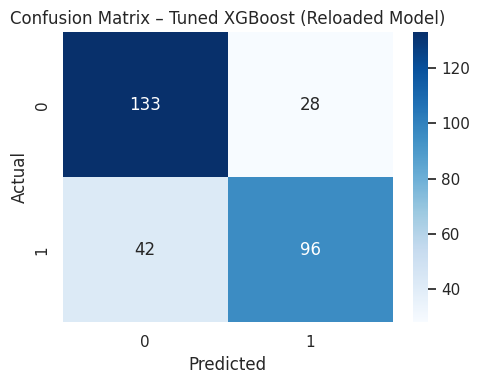

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_loaded)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix – Tuned XGBoost (Reloaded Model)")
plt.tight_layout()
plt.show()


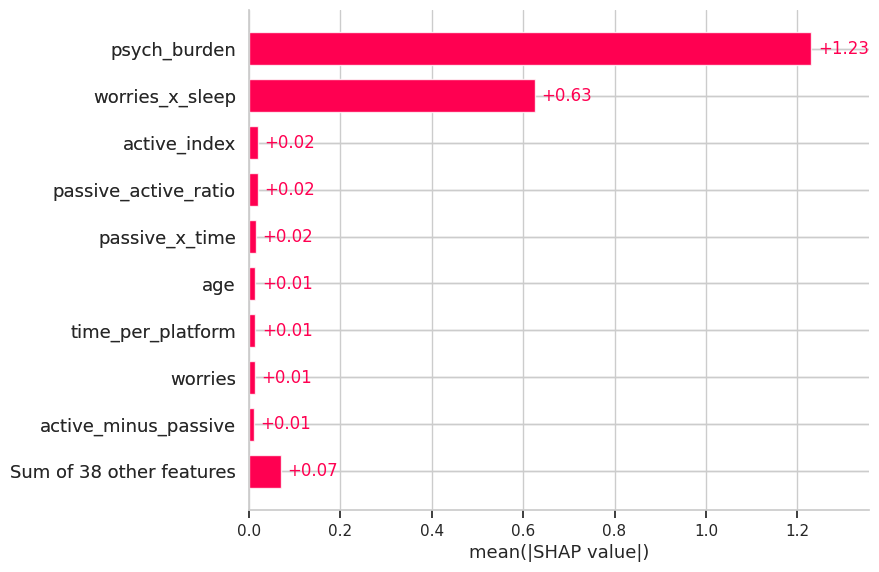

In [31]:
import shap

# Get the preprocessor and the actual XGBoost model from the pipeline
preprocessor_obj = loaded_model.named_steps['preprocessor']
xgb_model_obj = loaded_model.named_steps['model']

# Transform X_test to get data in the format expected by the xgb_model_obj
X_test_transformed = preprocessor_obj.transform(X_test)

# Get the feature names after one-hot encoding
numeric_feature_names = numeric_features # from cell 8
categorical_feature_names_out = preprocessor_obj.named_transformers_['cat'].get_feature_names_out(categorical_features) # from cell 8
all_feature_names = list(numeric_feature_names) + list(categorical_feature_names_out)

# Initialize explainer directly with the XGBoost model and the transformed data
# shap.Explainer will automatically detect it's a tree model and use TreeExplainer.
explainer = shap.Explainer(xgb_model_obj, X_test_transformed, feature_names=all_feature_names)

# Calculate SHAP values
shap_values = explainer(X_test_transformed)

# For binary classification, shap_values typically has an extra dimension for classes.
# However, for TreeExplainer with a classifier, it often explains the positive class directly
# or the raw margin output, making the 'values' attribute 2D.
# Therefore, we pass the Explanation object directly to shap.plots.bar.
shap.plots.bar(shap_values)

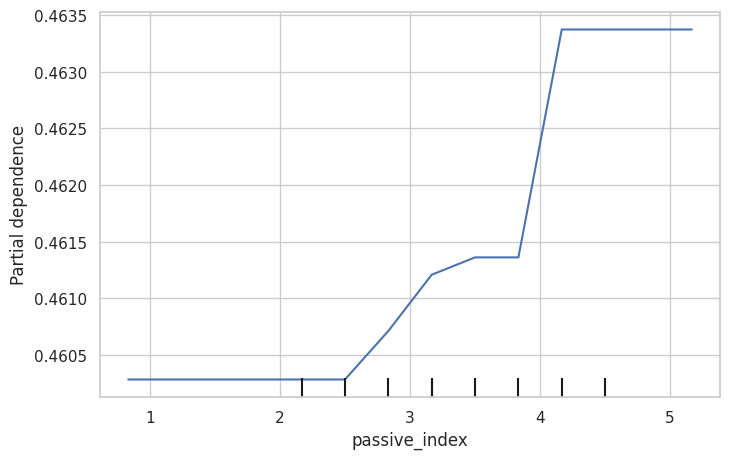

In [32]:
from sklearn.inspection import PartialDependenceDisplay

# Plot PDP
PartialDependenceDisplay.from_estimator(loaded_model, X, ['passive_index'])

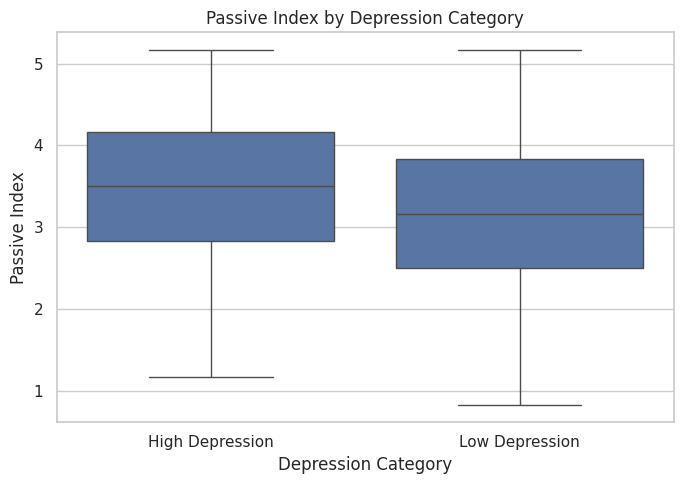

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a categorical column for depression based on 'depressed_high'
df['depression_category'] = df['depressed_high'].map({0: 'Low Depression', 1: 'High Depression'})

plt.figure(figsize=(7,5))
sns.boxplot(x="depression_category", y="passive_index", data=df)
plt.title("Passive Index by Depression Category")
plt.xlabel("Depression Category")
plt.ylabel("Passive Index")
plt.tight_layout()
plt.show()